# 1. Project Introduction and Business Problem

## Project Overview
This project analyzes Walmart's historical weekly sales data for 45 stores from February 2010 to October 2012. The objective is to identify sales trends, understand factors associated with weekly sales, compare store performance, and forecast sales for the next 12 weeks.

## Business Problem
Retail businesses need reliable sales insights to plan inventory, manage resources, and prepare for seasonal demand. This project uses historical Walmart sales data to examine how sales vary across stores and time periods and how factors such as holidays, temperature, fuel prices, CPI, and unemployment relate to sales.

## Project Objectives
- Clean and validate the dataset.
- Perform exploratory data analysis and identify potential outliers.
- Analyze holiday and seasonal sales patterns.
- Investigate relationships between sales and economic or environmental factors.
- Identify the best- and worst-performing stores.
- Compare forecasting models and predict weekly sales for all 45 stores for the next 12 weeks.

## Tools and Technologies
Python, Pandas, NumPy, Matplotlib, Seaborn, and Statsmodels in Google Colab.

## Expected Outcome
The project aims to deliver clear visualizations, store performance comparisons, forecast evaluations, and practical recommendations to support data-driven retail planning.

In [11]:

# ============================================
# WALMART CAPSTONE PROJECT
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Walmart dataset
file_path = "/content/Walmart DataSet.csv"
df = pd.read_csv(file_path)

# Display basic information
print("WALMART DATASET OVERVIEW")
print("-" * 40)

print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
display(df.isnull().sum().to_frame(name="Missing Count"))

print("\nDuplicate Rows:", df.duplicated().sum())


WALMART DATASET OVERVIEW
----------------------------------------
Dataset Shape: (6435, 8)

First 5 Rows:


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106



Column Names:
['Store', 'Date', 'Weekly_Sales', 'Holiday_Flag', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   object 
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), object(1)
memory usage: 402.3+ KB

Missing Values:


,Missing Count
Store,0
Date,0
Weekly_Sales,0
Holiday_Flag,0
Temperature,0
Fuel_Price,0
CPI,0
Unemployment,0



Duplicate Rows: 0


In [12]:
# ============================================

# Work on a copy of the original dataset
walmart = df.copy()

# Convert Date to datetime (day-month-year format)
walmart["Date"] = pd.to_datetime(
    walmart["Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

# Check date conversion
print("Invalid dates:", walmart["Date"].isna().sum())

# Check data types after conversion
print("\nUpdated Data Types:")
print(walmart.dtypes)

# Check duplicate records
print("\nDuplicate Rows:", walmart.duplicated().sum())

# Check unique stores
print("\nNumber of Stores:", walmart["Store"].nunique())
print("Store IDs:", sorted(walmart["Store"].unique()))

# Check weekly observations per store
print("\nObservations per Store:")
display(walmart.groupby("Store").size().describe())

# Check date range
print("\nDate Range:")
print("Start Date:", walmart["Date"].min().date())
print("End Date:", walmart["Date"].max().date())

# Check negative and zero weekly sales
print("\nZero Sales Records:", (walmart["Weekly_Sales"] == 0).sum())
print("Negative Sales Records:", (walmart["Weekly_Sales"] < 0).sum())

# Summary statistics
print("\nSummary Statistics:")
display(walmart.describe().round(2))


Invalid dates: 0

Updated Data Types:
Store                    int64
Date            datetime64[ns]
Weekly_Sales           float64
Holiday_Flag             int64
Temperature            float64
Fuel_Price             float64
CPI                    float64
Unemployment           float64
dtype: object

Duplicate Rows: 0

Number of Stores: 45
Store IDs: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(37), np.int64(38), np.int64(39), np.int64(40), np.int64(41), np.int64(42), np.int64(43), np.int64(44), np.int64(45)]

Observations per Store:


,0
count,45.0
mean,143.0
std,0.0
min,143.0
25%,143.0
50%,143.0
75%,143.0
max,143.0



Date Range:
Start Date: 2010-02-05
End Date: 2012-10-26

Zero Sales Records: 0
Negative Sales Records: 0

Summary Statistics:


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
count,6435.00,6435,6435.00,6435.00,6435.00,6435.00,6435.00,6435.00
mean,23.00,2011-06-17 00:00:00,1046964.88,0.07,60.66,3.36,171.58,8.00
min,1.00,2010-02-05 00:00:00,209986.25,0.00,-2.06,2.47,126.06,3.88
25%,12.00,2010-10-08 00:00:00,553350.10,0.00,47.46,2.93,131.74,6.89
50%,23.00,2011-06-17 00:00:00,960746.04,0.00,62.67,3.44,182.62,7.87
75%,34.00,2012-02-24 00:00:00,1420158.66,0.00,74.94,3.74,212.74,8.62
max,45.00,2012-10-26 00:00:00,3818686.45,1.00,100.14,4.47,227.23,14.31
std,12.99,NaN,564366.62,0.26,18.44,0.46,39.36,1.88


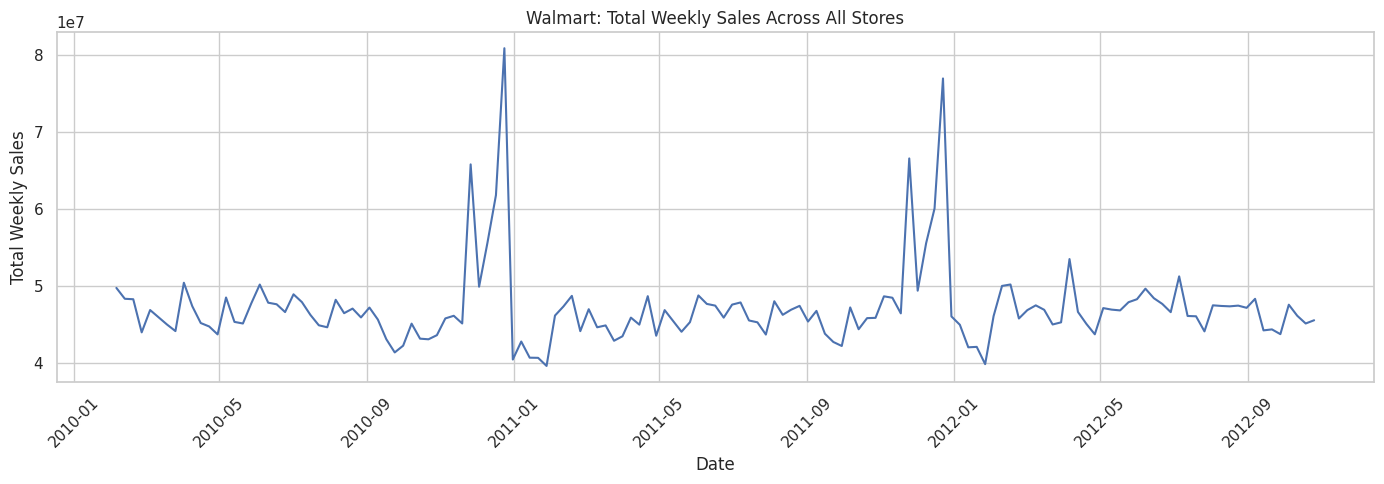

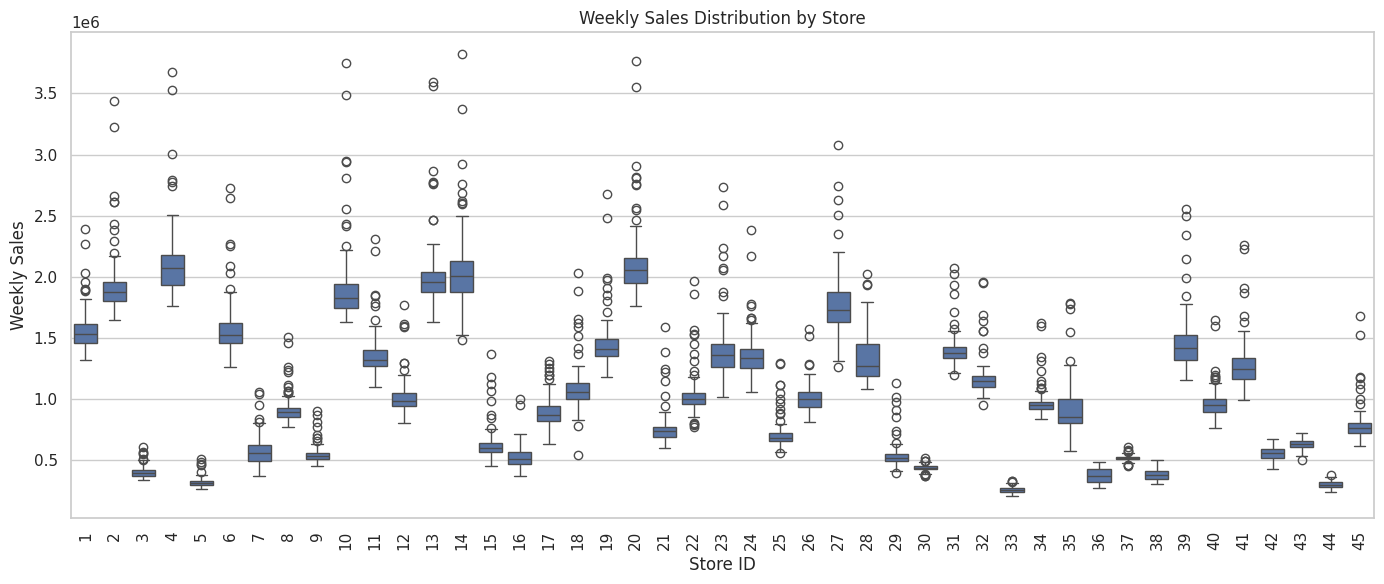

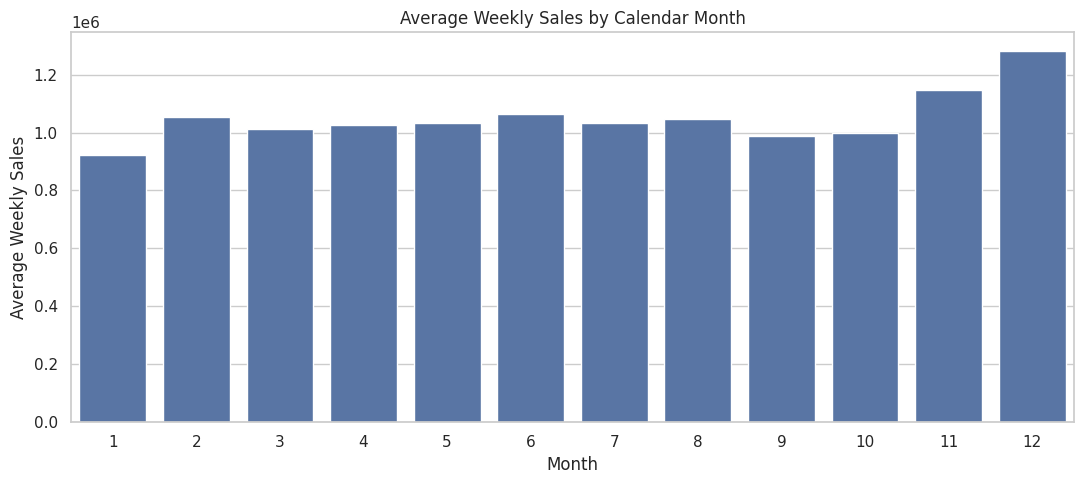

Holiday vs Non-Holiday Sales Summary


,mean,median,count
Holiday_Flag,,,
Non-Holiday,1041256.38,956211.20,5985
Holiday,1122887.89,1018538.04,450


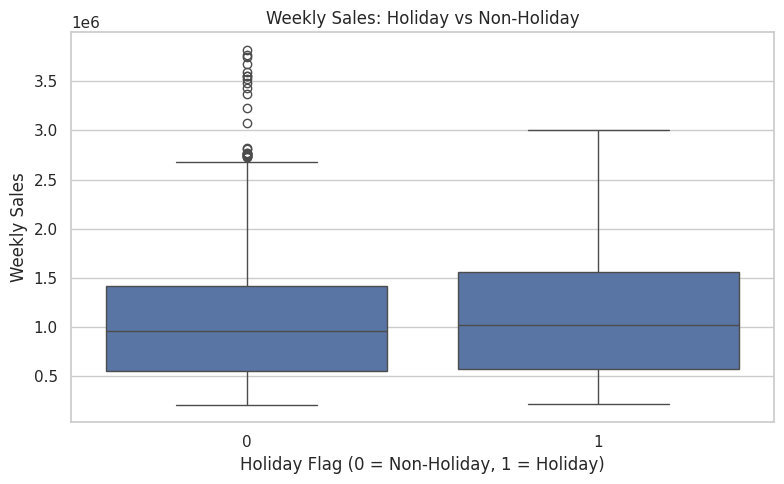

In [13]:

sns.set_theme(style="whitegrid", palette="deep")

# Ensure records are sorted chronologically within each store
walmart = walmart.sort_values(["Store", "Date"]).copy()

# Create date-related features
walmart["Year"] = walmart["Date"].dt.year
walmart["Month"] = walmart["Date"].dt.month
walmart["Week"] = walmart["Date"].dt.isocalendar().week.astype(int)

# 1. Overall weekly sales trend
overall_sales = (
    walmart.groupby("Date", as_index=False)["Weekly_Sales"]
    .sum()
    .sort_values("Date")
)

plt.figure(figsize=(14, 5))
sns.lineplot(
    data=overall_sales,
    x="Date",
    y="Weekly_Sales"
)
plt.title("Walmart: Total Weekly Sales Across All Stores")
plt.xlabel("Date")
plt.ylabel("Total Weekly Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 2. Sales distribution across stores
plt.figure(figsize=(14, 6))
sns.boxplot(
    data=walmart,
    x="Store",
    y="Weekly_Sales"
)
plt.title("Weekly Sales Distribution by Store")
plt.xlabel("Store ID")
plt.ylabel("Weekly Sales")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


# 3. Average weekly sales by month
monthly_sales = (
    walmart.groupby("Month", as_index=False)["Weekly_Sales"]
    .mean()
)

plt.figure(figsize=(11, 5))
sns.barplot(
    data=monthly_sales,
    x="Month",
    y="Weekly_Sales"
)
plt.title("Average Weekly Sales by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average Weekly Sales")
plt.tight_layout()
plt.show()


# 4. Holiday vs non-holiday sales
holiday_sales = (
    walmart.groupby("Holiday_Flag")["Weekly_Sales"]
    .agg(["mean", "median", "count"])
    .rename(index={0: "Non-Holiday", 1: "Holiday"})
)

print("Holiday vs Non-Holiday Sales Summary")
display(holiday_sales.round(2))

plt.figure(figsize=(8, 5))
sns.boxplot(
    data=walmart,
    x="Holiday_Flag",
    y="Weekly_Sales"
)
plt.title("Weekly Sales: Holiday vs Non-Holiday")
plt.xlabel("Holiday Flag (0 = Non-Holiday, 1 = Holiday)")
plt.ylabel("Weekly Sales")
plt.tight_layout()
plt.show()


### Seasonal Sales Trends and Business Interpretation

The exploratory analysis indicates that Walmart weekly sales tend to increase during major holiday periods, particularly toward the end of the year. Holiday weeks may experience higher customer demand because of seasonal shopping, holiday preparations, promotions, and increased purchasing activity.

The holiday versus non-holiday comparison in this dataset shows average weekly sales of approximately $1,122,888 during holiday weeks and $1,041,256 during non-holiday weeks, a difference of approximately 7.84%.

These results suggest that holiday periods are important for sales planning. However, the observed difference does not prove that holidays alone cause higher sales. Store characteristics, promotions, economic conditions, and the specific holiday period may also influence sales.


OUTLIER SUMMARY BY STORE


,Store,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
21,22,824288.71,1190121.60,14,9.79
24,25,559591.94,815305.80,12,8.39
7,8,746231.97,1038694.55,11,7.69
17,18,800438.81,1334145.65,10,6.99
19,20,1644384.56,2461667.28,10,6.99
33,34,831226.97,1068591.37,10,6.99
28,29,408091.68,638410.44,9,6.29
13,14,1494574.94,2504502.83,9,6.29
29,30,387528.71,490306.71,9,6.29
9,10,1435762.38,2249119.52,9,6.29



Total potential sales outliers: 300

HOLIDAY SALES SIGNIFICANCE TEST
Mean non-holiday sales: 1,041,256.38
Mean holiday sales:     1,122,887.89
Difference:             81,631.51
T-statistic:            2.6801
P-value:                0.007602
Result: Statistically significant difference at the 5% level.

CORRELATION MATRIX


,Weekly_Sales,Temperature,Fuel_Price,CPI,Unemployment
Weekly_Sales,1.000,-0.064,0.009,-0.073,-0.106
Temperature,-0.064,1.000,0.145,0.177,0.101
Fuel_Price,0.009,0.145,1.000,-0.171,-0.035
CPI,-0.073,0.177,-0.171,1.000,-0.302
Unemployment,-0.106,0.101,-0.035,-0.302,1.000


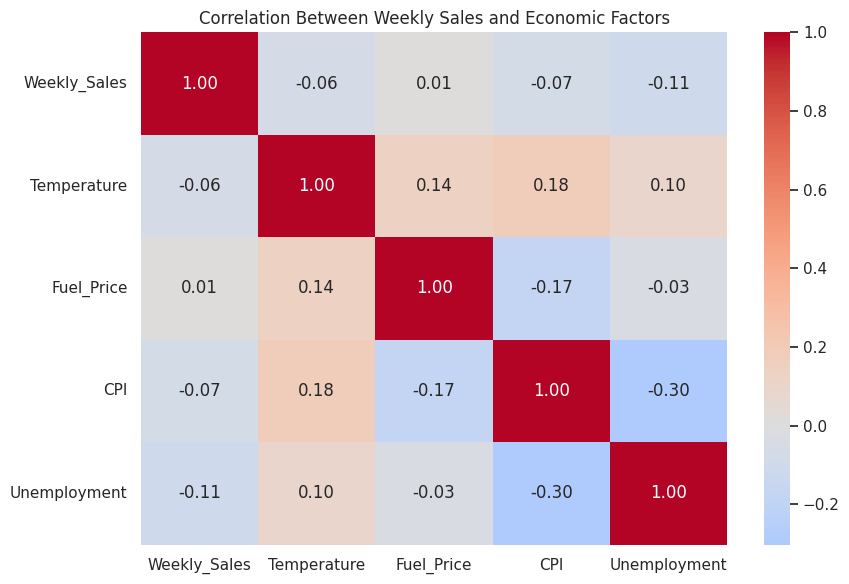


STORES WITH MOST NEGATIVE UNEMPLOYMENT CORRELATION


,Store,Unemployment_Correlation
37,38,-0.785
43,44,-0.780
38,39,-0.385
41,42,-0.356
40,41,-0.351
3,4,-0.337
16,17,-0.264
2,3,-0.230
36,37,-0.221
4,5,-0.207



Median store-wise unemployment correlation: -0.053


In [14]:
from scipy import stats

# --------------------------------------------
# Outlier detection using IQR per store
# --------------------------------------------

store_outlier_results = []

for store_id, group in walmart.groupby("Store"):
    q1 = group["Weekly_Sales"].quantile(0.25)
    q3 = group["Weekly_Sales"].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = group[
        (group["Weekly_Sales"] < lower_bound) |
        (group["Weekly_Sales"] > upper_bound)
    ]

    store_outlier_results.append({
        "Store": store_id,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": len(outliers),
        "Outlier_Percentage": len(outliers) / len(group) * 100
    })

outlier_summary = pd.DataFrame(store_outlier_results)

print("OUTLIER SUMMARY BY STORE")
display(
    outlier_summary.sort_values(
        "Outlier_Count", ascending=False
    ).head(10).round(2)
)

print(
    "\nTotal potential sales outliers:",
    outlier_summary["Outlier_Count"].sum()
)

# --------------------------------------------
# Holiday vs non-holiday statistical test
# --------------------------------------------

non_holiday = walmart.loc[
    walmart["Holiday_Flag"] == 0, "Weekly_Sales"
]

holiday = walmart.loc[
    walmart["Holiday_Flag"] == 1, "Weekly_Sales"
]

# Welch's t-test does not assume equal variances
t_stat, p_value = stats.ttest_ind(
    holiday,
    non_holiday,
    equal_var=False
)

print("\nHOLIDAY SALES SIGNIFICANCE TEST")
print(f"Mean non-holiday sales: {non_holiday.mean():,.2f}")
print(f"Mean holiday sales:     {holiday.mean():,.2f}")
print(f"Difference:             {holiday.mean() - non_holiday.mean():,.2f}")
print(f"T-statistic:            {t_stat:.4f}")
print(f"P-value:                {p_value:.6f}")

if p_value < 0.05:
    print("Result: Statistically significant difference at the 5% level.")
else:
    print("Result: No statistically significant difference at the 5% level.")

# --------------------------------------------
# Overall correlation matrix
# --------------------------------------------

variables = [
    "Weekly_Sales",
    "Temperature",
    "Fuel_Price",
    "CPI",
    "Unemployment"
]

correlation_matrix = walmart[variables].corr()

print("\nCORRELATION MATRIX")
display(correlation_matrix.round(3))

plt.figure(figsize=(9, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)
plt.title("Correlation Between Weekly Sales and Economic Factors")
plt.tight_layout()
plt.show()

# --------------------------------------------
# Store-wise unemployment relationship
# --------------------------------------------

unemployment_results = []

for store_id, group in walmart.groupby("Store"):
    corr = group["Weekly_Sales"].corr(group["Unemployment"])

    unemployment_results.append({
        "Store": store_id,
        "Unemployment_Correlation": corr
    })

unemployment_summary = pd.DataFrame(unemployment_results)

print("\nSTORES WITH MOST NEGATIVE UNEMPLOYMENT CORRELATION")
display(
    unemployment_summary.sort_values(
        "Unemployment_Correlation"
    ).head(10).round(3)
)

print(
    "\nMedian store-wise unemployment correlation:",
    round(unemployment_summary["Unemployment_Correlation"].median(), 3)
)


In [15]:

# --------------------------------------------
# Store-wise Temperature and CPI Analysis
# --------------------------------------------

store_factor_results = []

for store_id, group in walmart.groupby("Store"):
    store_factor_results.append({
        "Store": store_id,
        "Temperature_Correlation":
            group["Weekly_Sales"].corr(group["Temperature"]),
        "CPI_Correlation":
            group["Weekly_Sales"].corr(group["CPI"])
    })

store_factor_summary = pd.DataFrame(store_factor_results)

print("STORES WITH MOST NEGATIVE TEMPERATURE CORRELATION")
display(
    store_factor_summary.sort_values(
        "Temperature_Correlation"
    ).head(10).round(3)
)

print("STORES WITH MOST POSITIVE TEMPERATURE CORRELATION")
display(
    store_factor_summary.sort_values(
        "Temperature_Correlation", ascending=False
    ).head(10).round(3)
)

print("STORES WITH MOST NEGATIVE CPI CORRELATION")
display(
    store_factor_summary.sort_values(
        "CPI_Correlation"
    ).head(10).round(3)
)

print("STORES WITH MOST POSITIVE CPI CORRELATION")
display(
    store_factor_summary.sort_values(
        "CPI_Correlation", ascending=False
    ).head(10).round(3)
)

print("\nMEDIAN STORE-WISE CORRELATIONS")
print(
    "Temperature:",
    round(store_factor_summary["Temperature_Correlation"].median(), 3)
)
print(
    "CPI:",
    round(store_factor_summary["CPI_Correlation"].median(), 3)
)


STORES WITH MOST NEGATIVE TEMPERATURE CORRELATION


,Store,Temperature_Correlation,CPI_Correlation
9,10,-0.433,-0.115
11,12,-0.379,0.084
2,3,-0.378,0.317
27,28,-0.377,-0.096
29,30,-0.331,-0.298
7,8,-0.312,0.120
36,37,-0.300,0.245
1,2,-0.298,-0.062
33,34,-0.279,0.115
10,11,-0.279,0.070


STORES WITH MOST POSITIVE TEMPERATURE CORRELATION


,Store,Temperature_Correlation,CPI_Correlation
43,44,0.268,0.740
25,26,0.212,0.132
15,16,0.183,0.124
26,27,0.122,-0.213
23,24,0.112,-0.014
40,41,0.107,0.392
42,43,0.095,-0.286
39,40,0.091,0.113
16,17,0.081,0.349
38,39,0.065,0.428


STORES WITH MOST NEGATIVE CPI CORRELATION


,Store,Temperature_Correlation,CPI_Correlation
35,36,-0.094,-0.915
34,35,0.043,-0.424
13,14,-0.200,-0.420
29,30,-0.331,-0.298
42,43,0.095,-0.286
26,27,0.122,-0.213
17,18,-0.144,-0.194
14,15,-0.051,-0.174
20,21,-0.177,-0.164
18,19,-0.081,-0.155


STORES WITH MOST POSITIVE CPI CORRELATION


,Store,Temperature_Correlation,CPI_Correlation
37,38,0.033,0.813
43,44,0.268,0.740
38,39,0.065,0.428
40,41,0.107,0.392
41,42,-0.152,0.361
3,4,-0.226,0.351
16,17,0.081,0.349
2,3,-0.378,0.317
4,5,-0.176,0.308
8,9,-0.208,0.295



MEDIAN STORE-WISE CORRELATIONS
Temperature: -0.129
CPI: 0.084


### Interpretation of Temperature and CPI Relationships

The median store-wise correlation between temperature and weekly sales is -0.129, indicating a weak negative linear relationship. For a typical store, higher temperatures were associated with slightly lower weekly sales, although the relationship is too weak to support strong predictions from temperature alone.

The median store-wise correlation between CPI and weekly sales is +0.084, indicating a very weak positive linear relationship. This suggests that CPI has little linear association with weekly sales for a typical store in this dataset.

These findings vary by store and should not be interpreted as causal relationships. Walmart should consider historical sales, holiday periods, seasonality and store-specific patterns alongside economic and weather indicators when planning inventory and forecasting demand.


TOP 10 PERFORMING STORES


,Store,Total_Sales,Average_Weekly_Sales,Median_Weekly_Sales,Minimum_Weekly_Sales,Maximum_Weekly_Sales,Number_of_Weeks,Performance_Rank
0,20,3.013978e+08,2107676.87,2053165.41,1761016.51,3766687.43,143,1
1,4,2.995440e+08,2094712.96,2073951.38,1762539.30,3676388.98,143,2
2,14,2.889999e+08,2020978.40,2004330.30,1479514.66,3818686.45,143,3
3,13,2.865177e+08,2003620.31,1958823.56,1633663.12,3595903.20,143,4
4,2,2.753824e+08,1925751.34,1879107.31,1650394.44,3436007.68,143,5
5,10,2.716177e+08,1899424.57,1827521.71,1627707.31,3749057.69,143,6
6,27,2.538559e+08,1775216.20,1731935.43,1263534.86,3078162.08,143,7
7,6,2.237561e+08,1564728.19,1524390.07,1261253.18,2727575.18,143,8
8,1,2.224028e+08,1555264.40,1534849.64,1316899.31,2387950.20,143,9
9,39,2.074455e+08,1450668.13,1416005.59,1158698.44,2554482.84,143,10



BOTTOM 10 PERFORMING STORES


,Store,Total_Sales,Average_Weekly_Sales,Median_Weekly_Sales,Minimum_Weekly_Sales,Maximum_Weekly_Sales,Number_of_Weeks,Performance_Rank
35,29,77141554.31,539451.43,518628.42,395987.24,1130926.79,143,36
36,16,74252425.40,519247.73,508520.09,368600.00,1004730.69,143,37
37,37,74202740.32,518900.28,518124.16,451327.61,605791.46,143,38
38,30,62716885.12,438579.62,438068.71,369722.32,519354.88,143,39
39,3,57586735.07,402704.44,395107.35,339597.38,605990.41,143,40
40,38,55159626.42,385731.65,380870.09,303908.81,499267.66,143,41
41,36,53412214.97,373511.99,373267.58,270677.98,489372.02,143,42
42,5,45475688.90,318011.81,310338.17,260636.71,507900.07,143,43
43,44,43293087.84,302748.87,298080.45,241937.11,376233.89,143,44
44,33,37160221.96,259861.69,258427.39,209986.25,331173.51,143,45



HIGHEST VS LOWEST PERFORMING STORE
Highest-performing store: 20
Average weekly sales: 2107676.87
Lowest-performing store: 33
Average weekly sales: 259861.69
Absolute difference: 1847815.18
Difference relative to lowest-performing store: 711.08 %


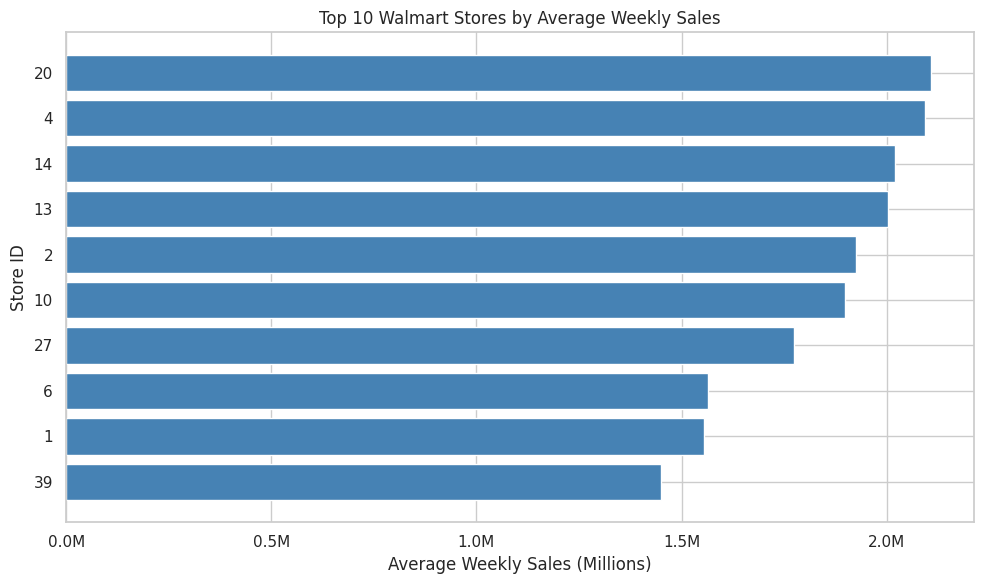


Store performance table saved successfully.


In [16]:
# Aggregate historical performance by store
store_performance = (
    walmart.groupby("Store")
    .agg(
        Total_Sales=("Weekly_Sales", "sum"),
        Average_Weekly_Sales=("Weekly_Sales", "mean"),
        Median_Weekly_Sales=("Weekly_Sales", "median"),
        Minimum_Weekly_Sales=("Weekly_Sales", "min"),
        Maximum_Weekly_Sales=("Weekly_Sales", "max"),
        Number_of_Weeks=("Weekly_Sales", "count")
    )
    .reset_index()
)

# Rank stores by average weekly sales
store_performance = store_performance.sort_values(
    "Average_Weekly_Sales", ascending=False
).reset_index(drop=True)

store_performance["Performance_Rank"] = (
    store_performance.index + 1
)

print("TOP 10 PERFORMING STORES")
display(store_performance.head(10).round(2))

print("\nBOTTOM 10 PERFORMING STORES")
display(store_performance.tail(10).round(2))

# Compare highest and lowest average weekly sales
best_store = store_performance.iloc[0]
worst_store = store_performance.iloc[-1]

sales_difference = (
    best_store["Average_Weekly_Sales"]
    - worst_store["Average_Weekly_Sales"]
)

percentage_difference = (
    sales_difference
    / worst_store["Average_Weekly_Sales"]
) * 100

print("\nHIGHEST VS LOWEST PERFORMING STORE")
print("Highest-performing store:", int(best_store["Store"]))
print(
    "Average weekly sales:",
    round(best_store["Average_Weekly_Sales"], 2)
)

print("Lowest-performing store:", int(worst_store["Store"]))
print(
    "Average weekly sales:",
    round(worst_store["Average_Weekly_Sales"], 2)
)

print("Absolute difference:", round(sales_difference, 2))
print(
    "Difference relative to lowest-performing store:",
    round(percentage_difference, 2), "%"
)

# Plot top 10 stores

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MultipleLocator, FuncFormatter

# Select top 10 stores and sort by average sales
top_10 = (
    store_performance
    .nlargest(10, "Average_Weekly_Sales")
    .sort_values("Average_Weekly_Sales")
    .copy()
)

fig, ax = plt.subplots(figsize=(10, 6))

# Plot the actual sales values explicitly
ax.barh(
    top_10["Store"].astype(str),
    top_10["Average_Weekly_Sales"],
    color="steelblue"
)

# Format the x-axis in millions
ax.xaxis.set_major_locator(MultipleLocator(500000))
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{x / 1_000_000:.1f}M")
)

ax.set_title("Top 10 Walmart Stores by Average Weekly Sales")
ax.set_xlabel("Average Weekly Sales (Millions)")
ax.set_ylabel("Store ID")

plt.tight_layout()
plt.show()



# Export ranking table for the final report
store_performance.to_csv(
    "walmart_store_performance.csv",
    index=False
)

print("\nStore performance table saved successfully.")


Store: 20
Number of observations: 143
Date range: 2010-02-05 00:00:00 to 2012-10-26 00:00:00
Missing weekly values: 0

Training observations: 131
Testing observations: 12

MODEL COMPARISON - STORE 20


,Model,MAE,RMSE
0,Seasonal Naive,83495.83,91250.61
1,Holt-Winters,49800.69,69729.04


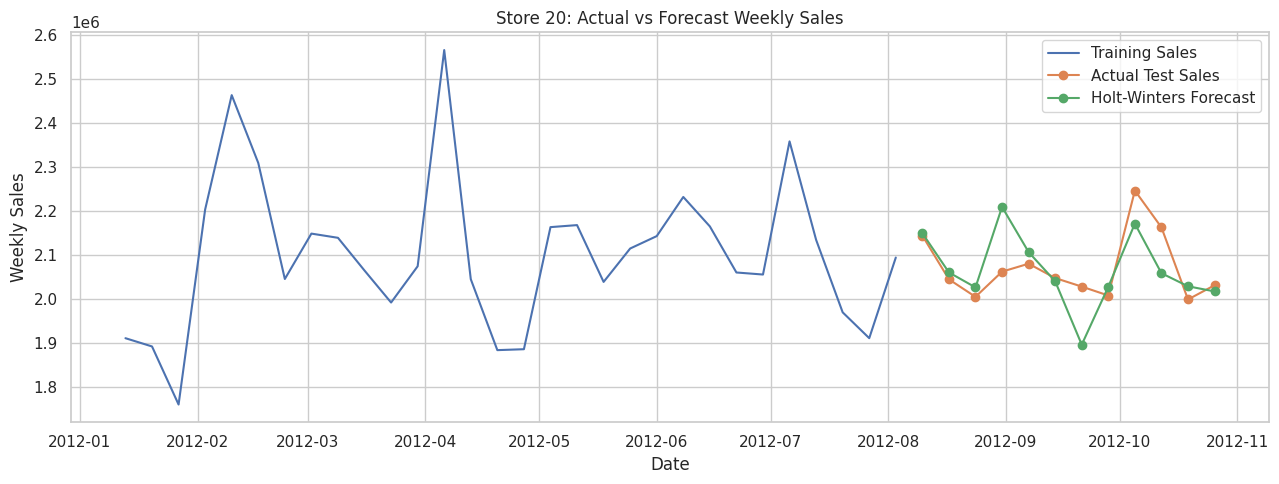

In [17]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Select Store 20 and prepare weekly sales series
store_id = 20

store_data = (
    walmart[walmart["Store"] == store_id]
    .sort_values("Date")
    .set_index("Date")["Weekly_Sales"]
    .asfreq("7D")
)

print("Store:", store_id)
print("Number of observations:", len(store_data))
print("Date range:", store_data.index.min(), "to", store_data.index.max())
print("Missing weekly values:", store_data.isna().sum())

# Chronological train/test split
train = store_data.iloc[:-12]
test = store_data.iloc[-12:]

print("\nTraining observations:", len(train))
print("Testing observations:", len(test))

# --------------------------------------------
# Model 1: Seasonal-naive baseline
# Use sales from 52 weeks earlier when available
# --------------------------------------------

seasonal_naive_forecast = store_data.shift(52).iloc[-12:]

# --------------------------------------------
# Model 2: Holt-Winters Exponential Smoothing
# Weekly data with annual seasonality
# --------------------------------------------

hw_model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal="add",
    seasonal_periods=52,
    initialization_method="estimated"
)

hw_fit = hw_model.fit(optimized=True)
hw_forecast = hw_fit.forecast(12)

# --------------------------------------------
# Evaluate both models
# --------------------------------------------

results = []

for model_name, predictions in [
    ("Seasonal Naive", seasonal_naive_forecast),
    ("Holt-Winters", hw_forecast)
]:
    predictions = pd.Series(
        np.asarray(predictions),
        index=test.index
    )

    results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(test, predictions),
        "RMSE": np.sqrt(mean_squared_error(test, predictions))
    })

model_results = pd.DataFrame(results)

print("\nMODEL COMPARISON - STORE 20")
display(model_results.round(2))

# --------------------------------------------
# Plot actual vs predicted sales
# --------------------------------------------

plt.figure(figsize=(13, 5))

plt.plot(
    train.index[-30:],
    train.iloc[-30:],
    label="Training Sales"
)

plt.plot(
    test.index,
    test,
    label="Actual Test Sales",
    marker="o"
)

plt.plot(
    test.index,
    hw_forecast,
    label="Holt-Winters Forecast",
    marker="o"
)

plt.title("Store 20: Actual vs Forecast Weekly Sales")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")
plt.legend()
plt.tight_layout()
plt.show()


In [18]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the cleaned dataset and sort chronologically
forecast_data = walmart.sort_values(["Store", "Date"]).copy()

HORIZON = 12
SEASON_LENGTH = 52

evaluation_results = []
future_forecasts = []

for store_id, group in forecast_data.groupby("Store"):

    # Build a regular weekly series
    series = (
        group.sort_values("Date")
        .set_index("Date")["Weekly_Sales"]
        .asfreq("7D")
    )

    if series.isna().any():
        print(f"Skipping Store {store_id}: missing weekly values")
        continue

    # Chronological train/test split
    train = series.iloc[:-HORIZON]
    test = series.iloc[-HORIZON:]

    # ----------------------------------------
    # Model 1: Seasonal-naive baseline
    # ----------------------------------------
    naive_predictions = series.shift(SEASON_LENGTH).loc[test.index]

    naive_mae = mean_absolute_error(test, naive_predictions)
    naive_rmse = np.sqrt(
        mean_squared_error(test, naive_predictions)
    )

    # ----------------------------------------
    # Model 2: Holt-Winters
    # ----------------------------------------
    try:
        hw_model = ExponentialSmoothing(
            train,
            trend="add",
            seasonal="add",
            seasonal_periods=SEASON_LENGTH,
            initialization_method="estimated"
        )

        hw_fit = hw_model.fit(optimized=True)
        hw_predictions = pd.Series(
            hw_fit.forecast(HORIZON).to_numpy(),
            index=test.index
        )

        hw_mae = mean_absolute_error(test, hw_predictions)
        hw_rmse = np.sqrt(
            mean_squared_error(test, hw_predictions)
        )

        best_model = (
            "Holt-Winters"
            if hw_rmse < naive_rmse
            else "Seasonal Naive"
        )

    except Exception as error:
        print(f"Store {store_id}: Holt-Winters failed - {error}")
        hw_mae = np.nan
        hw_rmse = np.nan
        best_model = "Seasonal Naive"

    evaluation_results.append({
        "Store": store_id,
        "Naive_MAE": naive_mae,
        "Naive_RMSE": naive_rmse,
        "HoltWinters_MAE": hw_mae,
        "HoltWinters_RMSE": hw_rmse,
        "Selected_Model": best_model
    })

    # ----------------------------------------
    # Refit selected model on all history
    # and forecast the next 12 weeks
    # ----------------------------------------
    future_dates = pd.date_range(
        start=series.index[-1] + pd.Timedelta(days=7),
        periods=HORIZON,
        freq="7D"
    )

    if best_model == "Holt-Winters":
        final_model = ExponentialSmoothing(
            series,
            trend="add",
            seasonal="add",
            seasonal_periods=SEASON_LENGTH,
            initialization_method="estimated"
        ).fit(optimized=True)

        predictions = final_model.forecast(HORIZON).to_numpy()

    else:
        # Future seasonal-naive values from 52 weeks earlier
        predictions = series.iloc[-SEASON_LENGTH:-SEASON_LENGTH + HORIZON].to_numpy()

    for date, prediction in zip(future_dates, predictions):
        future_forecasts.append({
            "Store": store_id,
            "Date": date,
            "Forecast_Weekly_Sales": max(0, float(prediction)),
            "Selected_Model": best_model
        })

# --------------------------------------------
# Results and model comparison
# --------------------------------------------
evaluation_df = pd.DataFrame(evaluation_results)
forecast_df = pd.DataFrame(future_forecasts)

print("MODEL SELECTION COUNTS")
display(
    evaluation_df["Selected_Model"]
    .value_counts()
    .to_frame("Number_of_Stores")
)

print("\nAVERAGE MODEL PERFORMANCE ACROSS STORES")
display(
    evaluation_df[
        ["Naive_MAE", "Naive_RMSE",
         "HoltWinters_MAE", "HoltWinters_RMSE"]
    ].mean().to_frame("Average_Error").round(2)
)

print("\nMODEL EVALUATION - FIRST 10 STORES")
display(evaluation_df.head(10).round(2))

print("\nFORECAST PREVIEW")
display(forecast_df.head(15).round(2))

print("\nTotal forecast rows:", len(forecast_df))
print("Stores forecasted:", forecast_df["Store"].nunique())
print("Forecast date range:",
      forecast_df["Date"].min().date(), "to",
      forecast_df["Date"].max().date())

# Save results
evaluation_df.to_csv("walmart_model_evaluation.csv", index=False)
forecast_df.to_csv("walmart_12_week_forecasts.csv", index=False)

print("\nSaved:")
print("- walmart_model_evaluation.csv")
print("- walmart_12_week_forecasts.csv")


MODEL SELECTION COUNTS


,Number_of_Stores
Selected_Model,
Holt-Winters,33
Seasonal Naive,12



AVERAGE MODEL PERFORMANCE ACROSS STORES


,Average_Error
Naive_MAE,53768.95
Naive_RMSE,64054.53
HoltWinters_MAE,43821.30
HoltWinters_RMSE,53110.11



MODEL EVALUATION - FIRST 10 STORES


,Store,Naive_MAE,Naive_RMSE,HoltWinters_MAE,HoltWinters_RMSE,Selected_Model
0,1,55165.05,66848.81,42570.57,52311.68,Holt-Winters
1,2,104826.94,115390.80,39019.27,47264.65,Holt-Winters
2,3,30587.90,32863.67,8048.84,10329.87,Holt-Winters
3,4,62698.65,74520.70,57238.33,71662.68,Holt-Winters
4,5,20385.04,22640.88,11329.99,12434.92,Holt-Winters
5,6,64088.28,72945.11,56720.97,71610.36,Holt-Winters
6,7,17119.68,21663.55,13107.04,15782.61,Holt-Winters
7,8,44910.15,54251.56,36883.54,42335.87,Holt-Winters
8,9,23306.65,27216.36,22677.56,26948.42,Holt-Winters
9,10,42955.55,56741.84,47315.74,64621.78,Seasonal Naive



FORECAST PREVIEW


,Store,Date,Forecast_Weekly_Sales,Selected_Model
0,1,2012-11-02,1690364.00,Holt-Winters
1,1,2012-11-09,1618979.95,Holt-Winters
2,1,2012-11-16,1594766.59,Holt-Winters
3,1,2012-11-23,2073041.06,Holt-Winters
4,1,2012-11-30,1653547.48,Holt-Winters
5,1,2012-12-07,1811620.85,Holt-Winters
6,1,2012-12-14,1983284.16,Holt-Winters
7,1,2012-12-21,2450605.23,Holt-Winters
8,1,2012-12-28,1503144.15,Holt-Winters
9,1,2013-01-04,1573177.13,Holt-Winters



Total forecast rows: 540
Stores forecasted: 45
Forecast date range: 2012-11-02 to 2013-01-18

Saved:
- walmart_model_evaluation.csv
- walmart_12_week_forecasts.csv


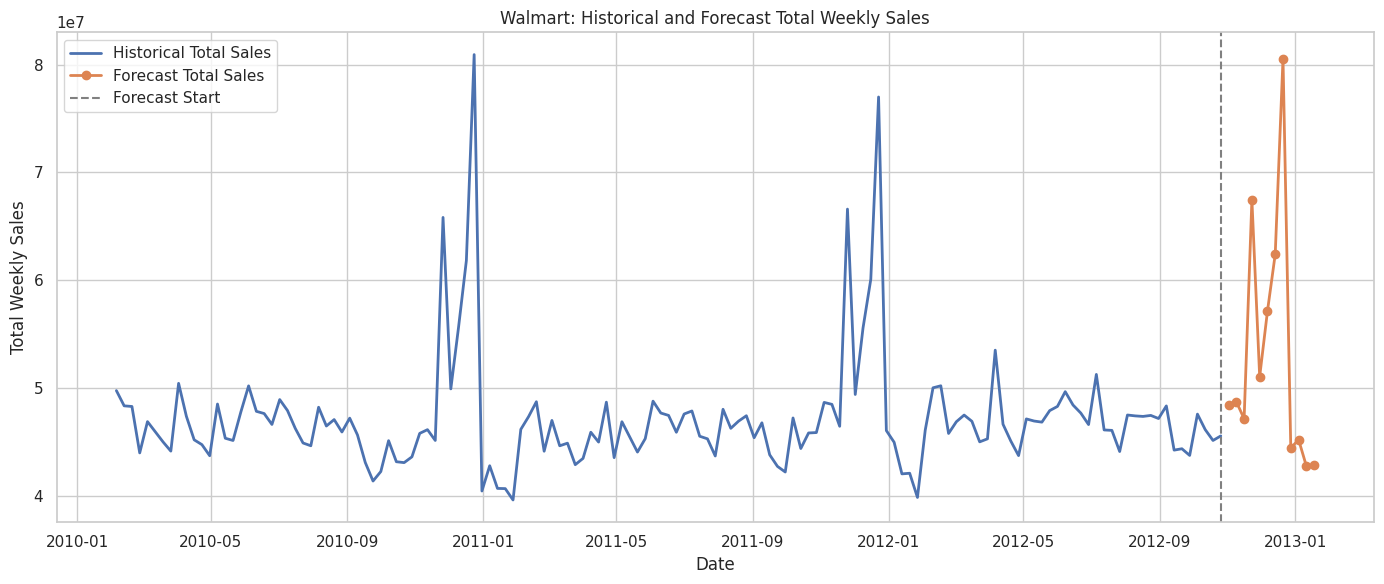

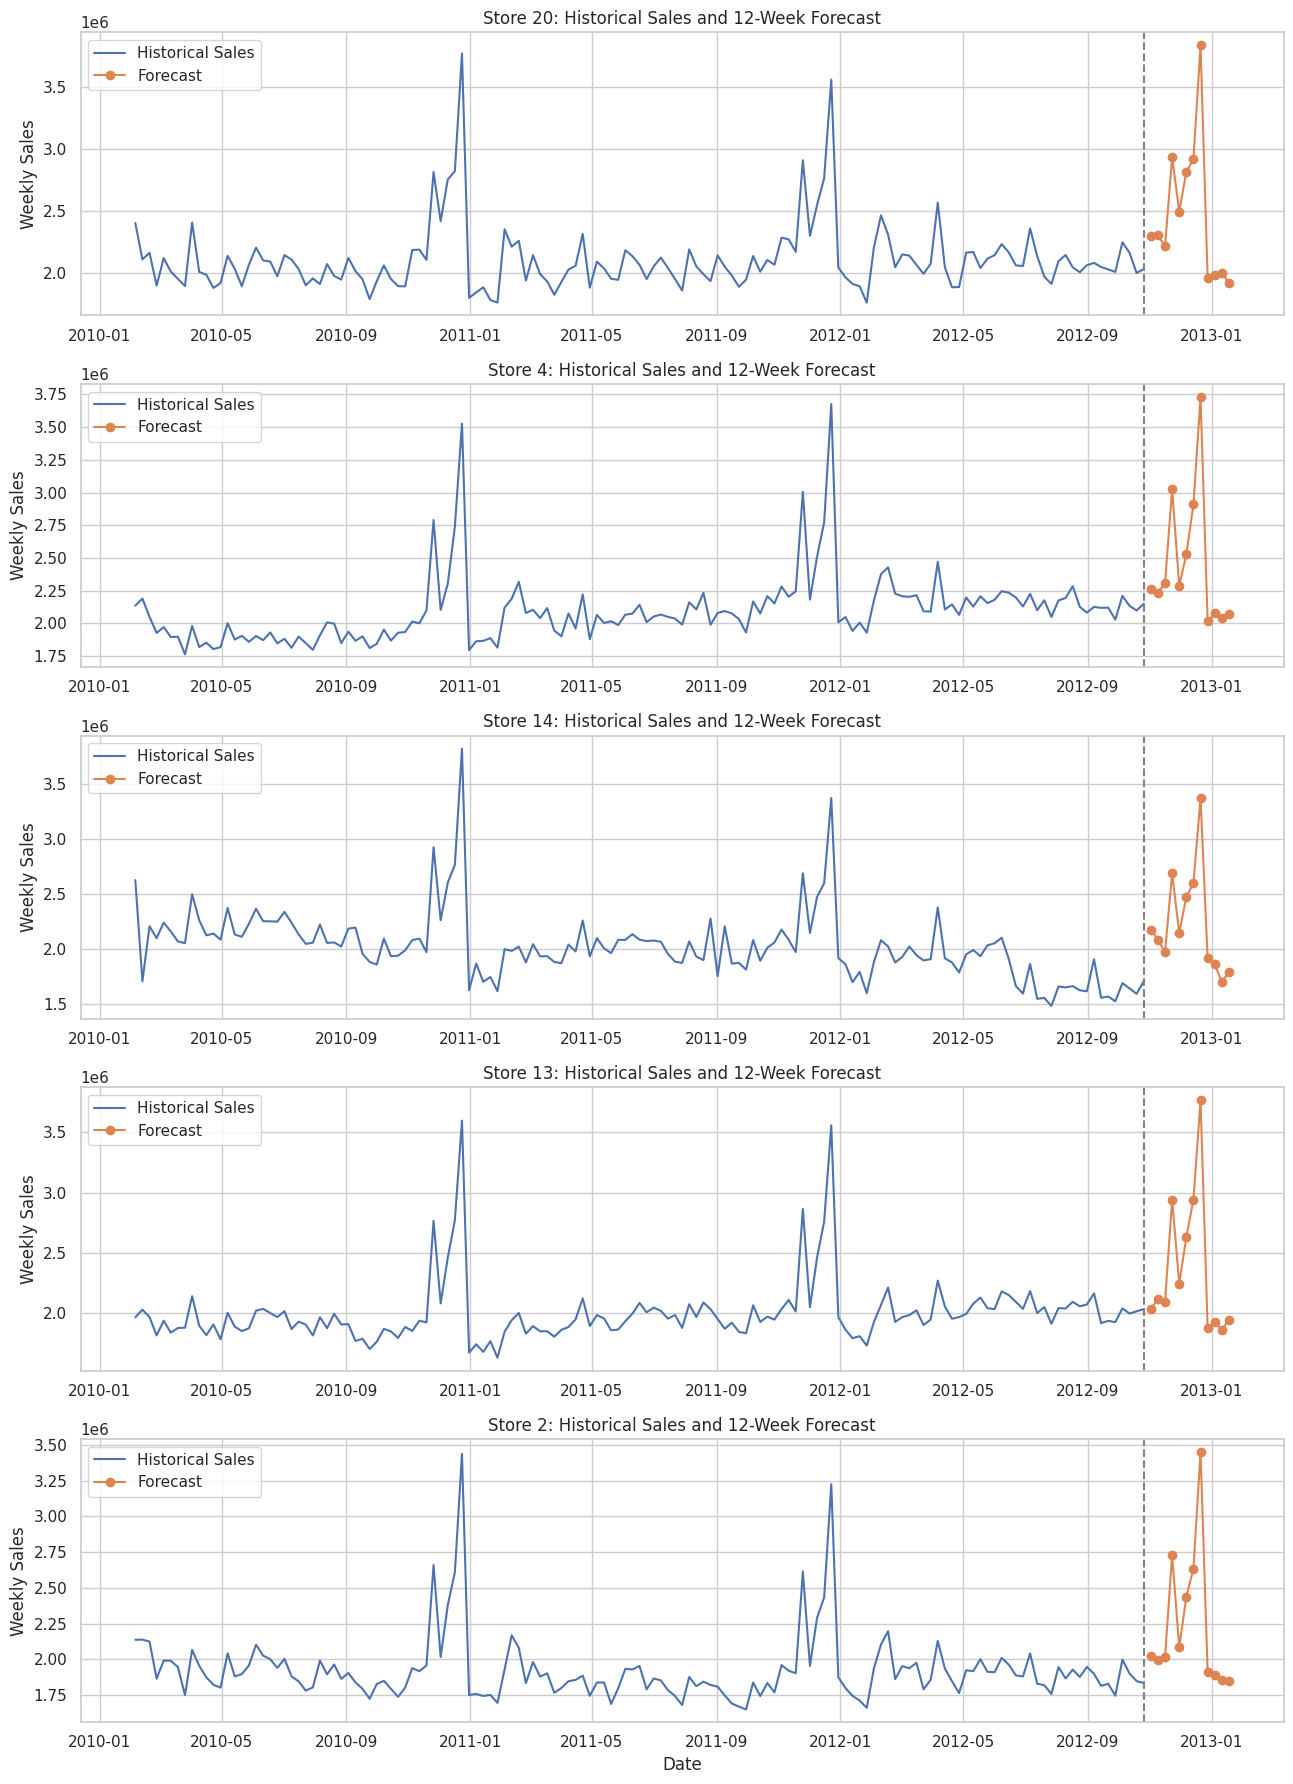

STORE-LEVEL FORECAST SUMMARY


,Store,Average_Forecast_Sales,Total_12_Week_Forecast,Minimum_Forecast,Maximum_Forecast,Selected_Model
19,20,2472107.04,29665284.54,1918364.18,3832608.11,Holt-Winters
3,4,2457069.46,29484833.48,2016163.08,3731388.36,Holt-Winters
12,13,2367428.62,28409143.46,1866650.60,3764381.67,Holt-Winters
1,2,2240229.71,26882756.48,1850600.41,3449472.26,Holt-Winters
13,14,2228837.77,26746053.27,1696248.27,3369068.99,Seasonal Naive
9,10,2195161.66,26341939.89,1675562.94,3487986.89,Seasonal Naive
26,27,1843559.86,22122718.29,1375571.43,2938308.74,Holt-Winters
38,39,1821881.04,21862572.46,1480486.99,2755714.33,Holt-Winters
5,6,1800444.37,21605332.38,1370871.08,2802880.00,Holt-Winters
0,1,1742200.93,20906411.18,1445058.22,2450605.23,Holt-Winters



Forecast summary saved: walmart_forecast_summary.csv


In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Ensure dates are datetime
forecast_df["Date"] = pd.to_datetime(forecast_df["Date"])

# --------------------------------------------
# 1. Combined forecast across all stores
# --------------------------------------------

combined_forecast = (
    forecast_df.groupby("Date", as_index=False)
    ["Forecast_Weekly_Sales"].sum()
)

historical_combined = (
    walmart.groupby("Date", as_index=False)
    ["Weekly_Sales"].sum()
)

plt.figure(figsize=(14, 6))

plt.plot(
    historical_combined["Date"],
    historical_combined["Weekly_Sales"],
    label="Historical Total Sales",
    linewidth=2
)

plt.plot(
    combined_forecast["Date"],
    combined_forecast["Forecast_Weekly_Sales"],
    label="Forecast Total Sales",
    marker="o",
    linewidth=2
)

plt.axvline(
    walmart["Date"].max(),
    linestyle="--",
    color="gray",
    label="Forecast Start"
)

plt.title("Walmart: Historical and Forecast Total Weekly Sales")
plt.xlabel("Date")
plt.ylabel("Total Weekly Sales")
plt.legend()
plt.tight_layout()
plt.show()


# --------------------------------------------
# 2. Forecast charts for top five stores
# --------------------------------------------

top_five_stores = (
    store_performance.head(5)["Store"].tolist()
)

fig, axes = plt.subplots(
    5, 1,
    figsize=(13, 18)
)

for ax, store_id in zip(axes, top_five_stores):

    historical = (
        walmart[walmart["Store"] == store_id]
        .sort_values("Date")
    )

    future = (
        forecast_df[forecast_df["Store"] == store_id]
        .sort_values("Date")
    )

    ax.plot(
        historical["Date"],
        historical["Weekly_Sales"],
        label="Historical Sales"
    )

    ax.plot(
        future["Date"],
        future["Forecast_Weekly_Sales"],
        marker="o",
        label="Forecast"
    )

    ax.axvline(
        historical["Date"].max(),
        linestyle="--",
        color="gray"
    )

    ax.set_title(f"Store {store_id}: Historical Sales and 12-Week Forecast")
    ax.set_ylabel("Weekly Sales")
    ax.legend()

plt.xlabel("Date")
plt.tight_layout()
plt.show()


# --------------------------------------------
# 3. Store-level forecast summary
# --------------------------------------------

forecast_summary = (
    forecast_df.groupby("Store")
    .agg(
        Average_Forecast_Sales=(
            "Forecast_Weekly_Sales", "mean"
        ),
        Total_12_Week_Forecast=(
            "Forecast_Weekly_Sales", "sum"
        ),
        Minimum_Forecast=(
            "Forecast_Weekly_Sales", "min"
        ),
        Maximum_Forecast=(
            "Forecast_Weekly_Sales", "max"
        )
    )
    .reset_index()
)

forecast_summary = forecast_summary.merge(
    evaluation_df[["Store", "Selected_Model"]],
    on="Store",
    how="left"
)

print("STORE-LEVEL FORECAST SUMMARY")
display(
    forecast_summary.sort_values(
        "Total_12_Week_Forecast",
        ascending=False
    ).head(10).round(2)
)

# Export summary
forecast_summary.to_csv(
    "walmart_forecast_summary.csv",
    index=False
)

print("\nForecast summary saved: walmart_forecast_summary.csv")


In [20]:
# FORECAST VALIDATION

# Compare future forecasts with corresponding sales
# from approximately 52 weeks earlier.

validation = forecast_df.copy()

validation["Comparable_Historical_Sales"] = validation.apply(
    lambda row: walmart.loc[
        (walmart["Store"] == row["Store"]) &
        (walmart["Date"] == row["Date"] - pd.Timedelta(weeks=52)),
        "Weekly_Sales"
    ].iloc[0]
    if (
        (walmart["Store"] == row["Store"]) &
        (walmart["Date"] == row["Date"] - pd.Timedelta(weeks=52))
    ).any()
    else np.nan,
    axis=1
)

validation["Forecast_vs_Historical_%"] = (
    (validation["Forecast_Weekly_Sales"] -
     validation["Comparable_Historical_Sales"])
    / validation["Comparable_Historical_Sales"]
) * 100

print("Forecast validation sample")
display(validation.head(15).round(2))

print("\nLargest forecast values")
display(
    validation.nlargest(
        10, "Forecast_Weekly_Sales"
    )[
        ["Store", "Date", "Forecast_Weekly_Sales",
         "Comparable_Historical_Sales",
         "Forecast_vs_Historical_%", "Selected_Model"]
    ].round(2)
)

print("\nForecast summary statistics")
display(
    forecast_df["Forecast_Weekly_Sales"]
    .describe()
    .to_frame("Forecast_Sales")
    .round(2)
)


Forecast validation sample


,Store,Date,Forecast_Weekly_Sales,Selected_Model,Comparable_Historical_Sales,Forecast_vs_Historical_%
0,1,2012-11-02,1690364.00,Holt-Winters,1697229.58,-0.40
1,1,2012-11-09,1618979.95,Holt-Winters,1594938.89,1.51
2,1,2012-11-16,1594766.59,Holt-Winters,1539483.70,3.59
3,1,2012-11-23,2073041.06,Holt-Winters,2033320.66,1.95
4,1,2012-11-30,1653547.48,Holt-Winters,1584083.95,4.39
5,1,2012-12-07,1811620.85,Holt-Winters,1799682.38,0.66
6,1,2012-12-14,1983284.16,Holt-Winters,1881176.67,5.43
7,1,2012-12-21,2450605.23,Holt-Winters,2270188.99,7.95
8,1,2012-12-28,1503144.15,Holt-Winters,1497462.72,0.38
9,1,2013-01-04,1573177.13,Holt-Winters,1550369.92,1.47



Largest forecast values


,Store,Date,Forecast_Weekly_Sales,Comparable_Historical_Sales,Forecast_vs_Historical_%,Selected_Model
235,20,2012-12-21,3832608.11,3555371.03,7.80,Holt-Winters
151,13,2012-12-21,3764381.67,3556766.03,5.84,Holt-Winters
43,4,2012-12-21,3731388.36,3676388.98,1.50,Holt-Winters
115,10,2012-12-21,3487986.89,3487986.89,0.00,Seasonal Naive
19,2,2012-12-21,3449472.26,3224369.80,6.98,Holt-Winters
163,14,2012-12-21,3369068.99,3369068.99,0.00,Seasonal Naive
39,4,2012-11-23,3023909.55,3004702.33,0.64,Holt-Winters
111,10,2012-11-23,2950198.64,2950198.64,0.00,Seasonal Naive
150,13,2012-12-14,2941959.65,2760346.71,6.58,Holt-Winters
147,13,2012-11-23,2941626.84,2864170.61,2.70,Holt-Winters



Forecast summary statistics


,Forecast_Sales
count,540.00
mean,1181551.62
std,701156.78
min,215359.21
25%,584817.12
50%,1052452.65
75%,1600128.46
max,3832608.11


# 11. Final Results and Business Recommendations

## Key Findings
- The dataset contains 6,435 records covering 45 Walmart stores, with 143 weekly observations per store.
- December had the highest average weekly sales among the months analyzed.
- Average sales during holiday weeks were approximately 7.84% higher than during non-holiday weeks. This is an observed difference, not proof that holidays alone caused higher sales.
- Store 20 had the highest average weekly sales, while Store 33 had the lowest.
- The average weekly sales difference between the best- and worst-performing stores was approximately $1.85 million.
- For the 12-week holdout evaluation across all stores, Holt-Winters achieved an average RMSE of approximately 53,110, compared with 64,055 for the seasonal-naive baseline.
- The selected models generated 12-week forecasts for all 45 stores, covering November 2, 2012, through January 18, 2013.

## Business Recommendations
1. **Seasonal planning:** Prepare inventory and staffing for the stronger sales periods observed around November and December.
2. **Store-specific strategies:** Study the practices of high-performing stores and investigate the business conditions affecting lower-performing stores before making operational changes.
3. **Forecast-based inventory management:** Use store-level forecasts as planning estimates and update them when new sales data becomes available.
4. **Economic factor monitoring:** Continue monitoring unemployment and other economic indicators, while recognizing that correlations do not establish causation.
5. **Model improvement:** Evaluate forecasting models over additional time periods and compare their performance before using forecasts for important business decisions.

## Limitations
This analysis uses historical data from 2010–2012. Relationships between sales and external factors are exploratory, and the forecast evaluation uses a single 12-week holdout period for each store. Actual future sales may differ from the predictions.

## Conclusion
The project demonstrates how Python-based exploratory analysis, store performance measurement, and time-series forecasting can support retail decision-making. The results provide a starting point for improving seasonal planning, inventory allocation, and store-level sales monitoring.